In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load cleaned dataset
df = pd.read_csv("../data/processed/car_price_cleaned.csv")

features = [
    "name", "year", "km_driven", "fuel",
    "seller_type", "transmission", "owner"
]

X = df[features].copy()
y = df["selling_price"].copy()

# Use the same split as Notebook 06
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Preprocessing
numeric_features = ["year", "km_driven"]
categorical_features = [
    "name", "fuel", "seller_type", "transmission", "owner"
]

preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numeric_features),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_features)
])

# Recreate both models
models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
        min_samples_leaf=2
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

print("Both models trained successfully!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Both models trained successfully!
Training records: 2861
Testing records: 716


In [6]:
results = []

for name, model in trained_models.items():
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    })

display(pd.DataFrame(results).round(4))

,Model,MAE,RMSE,R2
0,Random Forest,174156.8324,404521.2110,0.4920
1,Extra Trees,173899.7210,417335.9208,0.4593


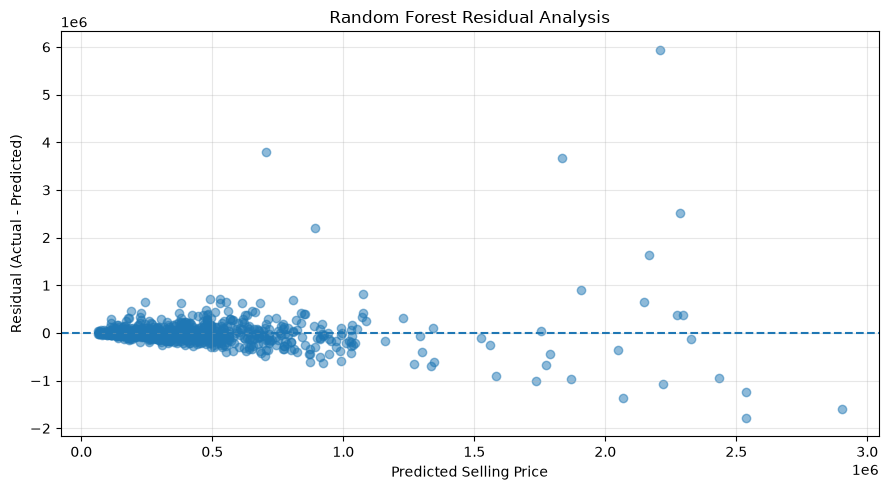

In [7]:
rf_predictions = trained_models["Random Forest"].predict(X_test)

residuals = y_test - rf_predictions

plt.figure(figsize=(9, 5))
plt.scatter(rf_predictions, residuals, alpha=0.5)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Selling Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random Forest Residual Analysis")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
diagnostics = pd.DataFrame({
    "actual_price": y_test,
    "predicted_price": rf_predictions
})

diagnostics["absolute_error"] = (
    diagnostics["actual_price"] - diagnostics["predicted_price"]
).abs()

diagnostics["price_group"] = pd.cut(
    diagnostics["actual_price"],
    bins=[0, 200_000, 500_000, 1_000_000, 2_000_000, float("inf")],
    labels=[
        "Up to 2 lakh",
        "2–5 lakh",
        "5–10 lakh",
        "10–20 lakh",
        "Above 20 lakh"
    ]
)

group_results = diagnostics.groupby(
    "price_group", observed=False
).agg(
    cars=("actual_price", "size"),
    median_actual_price=("actual_price", "median"),
    MAE=("absolute_error", "mean")
)

display(group_results.round(2))

,cars,median_actual_price,MAE
price_group,,,
Up to 2 lakh,184,130000.0,72570.29
2–5 lakh,304,325000.0,116035.99
5–10 lakh,178,675000.0,202858.63
10–20 lakh,39,1250000.0,455783.93
Above 20 lakh,11,3100000.0,2016728.00


In [9]:
diagnostics["signed_error"] = (
    diagnostics["actual_price"] - diagnostics["predicted_price"]
)

display(
    diagnostics.sort_values(
        "absolute_error", ascending=False
    ).head(15)
)

,actual_price,predicted_price,absolute_error,price_group,signed_error
76,8150000,2.208640e+06,5.941360e+06,Above 20 lakh,5.941360e+06
88,4500000,7.049596e+05,3.795040e+06,Above 20 lakh,3.795040e+06
3341,5500000,1.836491e+06,3.663509e+06,Above 20 lakh,3.663509e+06
2881,4800000,2.283888e+06,2.516112e+06,Above 20 lakh,2.516112e+06
927,3100000,8.930026e+05,2.206997e+06,Above 20 lakh,2.206997e+06
1703,750000,2.536372e+06,1.786372e+06,5–10 lakh,-1.786372e+06
538,3800000,2.168080e+06,1.631920e+06,Above 20 lakh,1.631920e+06
2562,1300000,2.902013e+06,1.602013e+06,10–20 lakh,-1.602013e+06
2882,710000,2.066165e+06,1.356165e+06,5–10 lakh,-1.356165e+06
3282,1300000,2.536372e+06,1.236372e+06,10–20 lakh,-1.236372e+06
